## Instalação de dependências

In [1]:
%%capture
!pip install -q -U "transformers>=4.44" "datasets>=2.20" "peft>=0.12" "accelerate>=0.33" \
                   "bitsandbytes>=0.43" "trl>=0.9" "evaluate" "sentencepiece"


In [2]:
import os, re, json, random, logging, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
    TrainingArguments, Trainer, DataCollatorForLanguageModeling,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# logging simples para auditoria (entrega 3: "implementar logging detalhado")
logging.basicConfig(
    filename="pipeline_finetuning.log",
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)
log = logging.getLogger("tech_challenge_fase3")
log.info("Início do pipeline de fine-tuning")


Device: cuda


## 1. Carregamento do dataset

In [3]:
!gdown --id "11bG57YsDHlf6S2m1-CuJxuL8wi-4UYmJ"

DATA_PATH = "medquad.csv"  # coloque o medquad.csv na mesma pasta do notebook

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head(3)


/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=11bG57YsDHlf6S2m1-CuJxuL8wi-4UYmJ
To: /content/medquad.csv
100% 22.8M/22.8M [00:00<00:00, 59.0MB/s]
Shape: (16412, 4)


,question,answer,source,focus_area
0,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
1,What causes Glaucoma ?,"Nearly 2.7 million people have glaucoma, a lea...",NIHSeniorHealth,Glaucoma
2,What are the symptoms of Glaucoma ?,Symptoms of Glaucoma Glaucoma can develop in ...,NIHSeniorHealth,Glaucoma


## 2. Exploração inicial (EDA)

In [4]:
print("Colunas:", df_raw.columns.tolist())
print("\nValores nulos por coluna:")
print(df_raw.isna().sum())

print("\nDistribuição por fonte (source):")
print(df_raw["source"].value_counts())

print("\nQtde. de focus_area distintos:", df_raw["focus_area"].nunique())

print("\nEstatísticas do tamanho das respostas (em caracteres):")
print(df_raw["answer"].dropna().str.len().describe())


Colunas: ['question', 'answer', 'source', 'focus_area']

Valores nulos por coluna:
question       0
answer         5
source         0
focus_area    14
dtype: int64

Distribuição por fonte (source):
source
GHR                  5430
GARD                 5394
NIDDK                1192
NINDS                1088
MPlusHealthTopics     981
NIHSeniorHealth       769
CancerGov             729
NHLBI                 559
CDC                   270
Name: count, dtype: int64

Qtde. de focus_area distintos: 5126

Estatísticas do tamanho das respostas (em caracteres):
count    16407.000000
mean      1303.452673
std       1656.694326
min          6.000000
25%        487.000000
50%        890.000000
75%       1589.000000
max      29046.000000
Name: answer, dtype: float64


## 3. Pré-processamento e limpeza

In [5]:
def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\s+", " ", text)           # espaços/quebras de linha múltiplos
    text = re.sub(r"&nbsp;|&amp;|&quot;", " ", text)
    text = text.strip()
    return text

df = df_raw.dropna(subset=["question", "answer"]).copy()
df["question"] = df["question"].map(clean_text)
df["answer"] = df["answer"].map(clean_text)
df["focus_area"] = df["focus_area"].fillna("Não especificado").map(clean_text)

before = len(df)
df = df.drop_duplicates(subset=["question", "answer"]).reset_index(drop=True)
print(f"Duplicatas exatas removidas: {before - len(df)}")
print("Shape após limpeza:", df.shape)


Duplicatas exatas removidas: 48
Shape após limpeza: (16359, 4)


## 4. Anonimização

In [6]:
PII_PATTERNS = {
    "EMAIL": re.compile(r"[\w\.-]+@[\w\.-]+\.\w+"),
    "PHONE": re.compile(r"\b(?:\+?\d{1,3}[ -]?)?(?:\(?\d{2,3}\)?[ -]?)?\d{4,5}[ -]?\d{4}\b"),
    "CPF": re.compile(r"\b\d{3}\.?\d{3}\.?\d{3}-?\d{2}\b"),
    "SSN_LIKE": re.compile(r"\b\d{3}-\d{2}-\d{4}\b"),
    "DATE_DDMMYYYY": re.compile(r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b"),
}

def anonymize(text: str) -> str:
    for label, pattern in PII_PATTERNS.items():
        text = pattern.sub(f"[{label}_REDACTED]", text)
    return text

n_hits = 0
for col in ["question", "answer"]:
    hits = df[col].map(lambda t: any(p.search(t) for p in PII_PATTERNS.values())).sum()
    n_hits += hits
    df[col] = df[col].map(anonymize)

print(f"Ocorrências de possíveis PII encontradas e mascaradas: {n_hits}")
log.info(f"Anonimização concluída. Ocorrências mascaradas: {n_hits}")


Ocorrências de possíveis PII encontradas e mascaradas: 43


## 5. Curadoria


In [7]:
MIN_CHARS, MAX_CHARS = 40, 2500
SAMPLE_SIZE = 6000  # None = usa o dataset inteiro

mask = df["answer"].str.len().between(MIN_CHARS, MAX_CHARS) & df["question"].str.len().ge(10)
df_cur = df[mask].reset_index(drop=True)
print(f"Removidas por tamanho fora do intervalo: {len(df) - len(df_cur)}")

if SAMPLE_SIZE and len(df_cur) > SAMPLE_SIZE:
    df_cur = (
        df_cur.groupby("source", group_keys=False)
        .apply(lambda g: g.sample(
            min(len(g), max(1, int(SAMPLE_SIZE * len(g) / len(df_cur)))),
            random_state=SEED))
        .sample(frac=1, random_state=SEED)  # embaralha
        .reset_index(drop=True)
    )

print("Shape final curado:", df_cur.shape)
df_cur["source"].value_counts()


Removidas por tamanho fora do intervalo: 1489
Shape final curado: (5995, 4)


/tmp/ipykernel_464/1877767717.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(


,count
source,
GHR,2124
GARD,2003
NINDS,436
MPlusHealthTopics,395
NIDDK,386
NIHSeniorHealth,247
CancerGov,179
NHLBI,134
CDC,91


## 6. Formatação como dataset de instrução


In [8]:
SYSTEM_PROMPT = (
    "Você é um assistente médico virtual do hospital, treinado para apoiar médicos com "
    "informações baseadas em protocolos e literatura clínica. "
    "Responda de forma objetiva e cite que a informação é de caráter educativo. "
    "NUNCA prescreva medicação ou defina conduta final sem indicar que é necessária "
    "validação humana por um profissional habilitado."
)

def build_example(row):
    return {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": row["question"]},
            {"role": "assistant", "content": row["answer"] + \
                f"\n\n[Fonte: {row['source']} | Tema: {row['focus_area']}]"},
        ]
    }

records = df_cur.apply(build_example, axis=1).tolist()
print(json.dumps(records[0], indent=2, ensure_ascii=False)[:800])


{
  "messages": [
    {
      "role": "system",
      "content": "Você é um assistente médico virtual do hospital, treinado para apoiar médicos com informações baseadas em protocolos e literatura clínica. Responda de forma objetiva e cite que a informação é de caráter educativo. NUNCA prescreva medicação ou defina conduta final sem indicar que é necessária validação humana por um profissional habilitado."
    },
    {
      "role": "user",
      "content": "How many people are affected by cartilage-hair hypoplasia ?"
    },
    {
      "role": "assistant",
      "content": "Cartilage-hair hypoplasia occurs most often in the Old Order Amish population, where it affects about 1 in 1,300 newborns. In people of Finnish descent, its incidence is approximately 1 in 20,000. Outside of these popul


## 7. Split treino / validação / teste (80/10/10)

In [9]:
ds_full = Dataset.from_list(records).shuffle(seed=SEED)
n = len(ds_full)
n_train = int(n * 0.8)
n_val = int(n * 0.1)

dataset = DatasetDict({
    "train": ds_full.select(range(0, n_train)),
    "validation": ds_full.select(range(n_train, n_train + n_val)),
    "test": ds_full.select(range(n_train + n_val, n)),
})
print(dataset)

# salva os splits em JSONL — serão reaproveitados depois como base de conhecimento
# (ex.: retrieval) no pipeline LangChain da entrega 2
Path("data_curada").mkdir(exist_ok=True)
for split, d in dataset.items():
    d.to_json(f"data_curada/medquad_{split}.jsonl", orient="records", lines=True, force_ascii=False)
print("Arquivos salvos em ./data_curada/")


DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 4796
    })
    validation: Dataset({
        features: ['messages'],
        num_rows: 599
    })
    test: Dataset({
        features: ['messages'],
        num_rows: 600
    })
})


Creating json from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Arquivos salvos em ./data_curada/


## 8. Modelo base e tokenizer

In [10]:
BASE_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    quantization_config=bnb_config if DEVICE == "cuda" else None,
    device_map="auto" if DEVICE == "cuda" else None,
    torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
)
log.info(f"Modelo base carregado: {BASE_MODEL}")


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 9. Tokenização

In [11]:
MAX_LEN = 1024

def tokenize_fn(example):
    text = tokenizer.apply_chat_template(
        example["messages"], tokenize=False, add_generation_prompt=False
    )
    tokens = tokenizer(
        text, truncation=True, max_length=MAX_LEN, padding="max_length"
    )
    tokens["labels"] = tokens["input_ids"].copy()
    return tokens

tokenized = dataset.map(tokenize_fn, remove_columns=["messages"])
tokenized.set_format(type="torch")
print(tokenized)


Map:   0%|          | 0/4796 [00:00<?, ? examples/s]

Map:   0%|          | 0/599 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 4796
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 599
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 600
    })
})


## 10. Configuração do LoRA (fine-tuning parameter-efficient)

In [12]:
model = prepare_model_for_kbit_training(model) if DEVICE == "cuda" else model

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


## 11. Treinamento

In [13]:
training_args = TrainingArguments(
    output_dir="checkpoints_medquad_lora",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    #num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=100,
    max_steps=10,
    logging_steps=20,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=200,
    save_total_limit=2,
    bf16=(DEVICE == "cuda"),
    report_to="none",
    seed=SEED,
)

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator,
)

log.info("Início do treinamento LoRA")
train_result = trainer.train()
log.info(f"Treinamento concluído. Métricas: {train_result.metrics}")
train_result.metrics

Step,Training Loss,Validation Loss
10,No log,2.703591


{'train_runtime': 657.5978,
 'train_samples_per_second': 0.243,
 'train_steps_per_second': 0.015,
 'total_flos': 353954168832000.0,
 'train_loss': 2.746649169921875,
 'epoch': 0.03336113427856547}

## 12. Salvando o adapter fine-tuned

In [14]:
FINAL_DIR = "modelo_medquad_lora_final"
trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
log.info(f"Adapter salvo em {FINAL_DIR}")
print("Salvo em:", FINAL_DIR)


Salvo em: modelo_medquad_lora_final


## 13. Avaliação quantitativa — perplexidade (antes vs. depois)

In [15]:
import math

def compute_perplexity(trainer, dataset):
    metrics = trainer.evaluate(eval_dataset=dataset)
    return math.exp(metrics["eval_loss"]), metrics

ppl_finetuned, metrics_ft = compute_perplexity(trainer, tokenized["test"])
print(f"Perplexidade (modelo fine-tuned) no teste: {ppl_finetuned:.2f}")

# Para comparar com o modelo base "puro", recarregue-o sem o adapter LoRA
# e rode trainer.evaluate novamente (requer memória extra na GPU).

Training Loss,Validation Loss,Step
No log,2.719463,10


Perplexidade (modelo fine-tuned) no teste: 15.17


## 14. Avaliação qualitativa e explainability

In [16]:
def ask(question, max_new_tokens=200):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=True,
            temperature=0.7, top_p=0.9, pad_token_id=tokenizer.eos_token_id,
        )
    resposta = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    log.info(f"PERGUNTA: {question} | RESPOSTA: {resposta[:200]}...")
    return resposta

amostras_teste = dataset["test"].select(range(3))
for ex in amostras_teste:
    pergunta = ex["messages"][1]["content"]
    referencia = ex["messages"][2]["content"]
    print("PERGUNTA:", pergunta)
    print("\nRESPOSTA DO MODELO FINE-TUNED:\n", ask(pergunta))
    print("\nRESPOSTA DE REFERÊNCIA (dataset):\n", referencia[:400], "...")
    print("=" * 100)


PERGUNTA: Do you have information about Drug Safety

RESPOSTA DO MODELO FINE-TUNED:
 Yes, I can provide you with information on drug safety and medical protocols for reference. Please note that I am a virtual assistant designed to be helpful and informative in providing accurate information, but I cannot prescribe medication or define the appropriate response without professional guidance from healthcare professionals.

RESPOSTA DE REFERÊNCIA (dataset):
 Summary : In the U.S., the government's Food and Drug Administration (FDA) must approve any drug before it can be sold. This is true whether it's a prescription or an over-the-counter drug. The FDA evaluates the safety of a drug by looking at - Side effects - How it's manufactured - Results of animal testing and clinical trials The FDA also monitors a drug's safety after approval. For you, drug sa ...
PERGUNTA: What to do for Alzheimer's Caregiving ?

RESPOSTA DO MODELO FINE-TUNED:
 Caring for someone with Alzheimer's Disease can be ch

---
# FASE 2 — Assistente médico com LangChain + LangGraph

## Objetivo desta fase
Criar um **assistente virtual médico** que:
1. Integra a LLM fine-tuned da Fase 1 via **LangChain**;
2. Consulta uma **base estruturada de prontuários** (dados sintéticos anonimizados);
3. Contextualiza respostas com informações atualizadas do paciente;
4. Orquestra um **fluxo de decisão** com **LangGraph** (exames pendentes → sugestão → alerta);
5. Aplica **guardrails** (nunca fecha conduta sem validação humana), **logging** de auditoria e **explainability** (citar fontes).


## 15. Instalação das dependências

Pacotes usados:
- `langchain` / `langchain-core` / `langchain-community`: orquestração do pipeline
- `langgraph`: máquina de estados do fluxo clínico automatizado
- `langchain-huggingface`: ponte entre o modelo Hugging Face e o LangChain


In [17]:
%%capture
!pip install -q -U "langchain>=0.3" "langchain-core>=0.3" "langchain-community>=0.3" \
                   "langgraph>=0.2" "langchain-huggingface>=0.1" "sqlalchemy>=2.0"


### 16. Imports e configuração de auditoria (Fase 2)

Mantemos um logger dedicado (`assistente_medico.log`) para rastrear consultas à base de prontuários, decisões do fluxo LangGraph, bloqueios de segurança (guardrails) e fontes usadas na resposta (explainability).


In [18]:
import os, json, sqlite3, logging, uuid, textwrap, datetime as dt, re
from pathlib import Path
from typing import Any, Dict, List, Optional, TypedDict, Annotated
from operator import add

import pandas as pd
import torch

# LangChain / LangGraph
from langchain_core.tools import tool
from langchain_core.runnables import RunnableLambda
from langgraph.graph import StateGraph, END, START

# Logging detalhado — requisito 3 (segurança e validação / auditoria)
LOG_ASSISTENTE = "assistente_medico.log"
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
    handlers=[
        logging.FileHandler(LOG_ASSISTENTE, encoding="utf-8"),
        logging.StreamHandler(),  # também no console do Colab
    ],
    force=True,  # sobrescreve handlers da Fase 1 se já existirem
)
alog = logging.getLogger("assistente_medico")
alog.info("=" * 60)
alog.info("Início da Fase 2 — Assistente médico LangChain/LangGraph")
alog.info("=" * 60)

# Diretórios de artefatos (compartilhados com a Fase 1)
ADAPTER_DIR = Path("modelo_medquad_lora_final")
DB_PATH = Path("hospital_prontuarios.db")
AUDIT_JSONL = Path("auditoria_respostas.jsonl")

print("Adapter existe?", ADAPTER_DIR.exists())
print("Log do assistente:", LOG_ASSISTENTE)


2026-11-23 15:12:23,044 | INFO | assistente_medico | ============================================================
2026-11-23 15:12:23,050 | INFO | assistente_medico | Início da Fase 2 — Assistente médico LangChain/LangGraph
2026-11-23 15:12:23,052 | INFO | assistente_medico | ============================================================


Adapter existe? True
Log do assistente: assistente_medico.log


## 17. Carregar a LLM customizada (bridge Hugging Face → LangChain)

Estratégia:
1. Preferir o **adapter LoRA** salvo na Fase 1 (`modelo_medquad_lora_final`).
2. Se não existir, usar o **modelo base** `Qwen/Qwen2.5-0.5B-Instruct` (fluxo ainda demonstrável).
3. Expor a geração via uma função compatível com LangChain (`RunnableLambda`), para não depender de APIs pagas.


In [19]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

# Reaproveita constantes da Fase 1 se já existirem no kernel; senão define fallback
BASE_MODEL = globals().get("BASE_MODEL", "Qwen/Qwen2.5-0.5B-Instruct")
DEVICE = globals().get("DEVICE", "cuda" if torch.cuda.is_available() else "cpu")
SYSTEM_PROMPT = globals().get(
    "SYSTEM_PROMPT",
    (
        "Você é um assistente médico virtual do hospital, treinado para apoiar médicos com "
        "informações baseadas em protocolos e literatura clínica. "
        "Responda de forma objetiva e cite que a informação é de caráter educativo. "
        "NUNCA prescreva medicação ou defina conduta final sem indicar que é necessária "
        "validação humana por um profissional habilitado."
    ),
)


def carregar_llm_customizada():
    # Carrega tokenizer + modelo (com LoRA se disponível) para geração local.
    alog.info(f"Carregando tokenizer/modelo: {BASE_MODEL} | device={DEVICE}")

    tok = AutoTokenizer.from_pretrained(
        str(ADAPTER_DIR) if ADAPTER_DIR.exists() else BASE_MODEL
    )
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token

    bnb = None
    if DEVICE == "cuda":
        bnb = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.bfloat16,
            bnb_4bit_use_double_quant=True,
        )

    base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL,
        quantization_config=bnb,
        device_map="auto" if DEVICE == "cuda" else None,
        torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
    )

    if ADAPTER_DIR.exists():
        mdl = PeftModel.from_pretrained(base, str(ADAPTER_DIR))
        alog.info(f"Adapter LoRA carregado de {ADAPTER_DIR}")
        modo = "fine-tuned (LoRA)"
    else:
        mdl = base
        alog.warning("Adapter LoRA NÃO encontrado — usando modelo base (demo do fluxo)")
        modo = "base (sem fine-tuning)"

    mdl.eval()
    return tok, mdl, modo


# Se a Fase 1 já deixou model/tokenizer no kernel E o adapter existe, reutilizamos
_reuse = (
    "model" in globals()
    and "tokenizer" in globals()
    and ADAPTER_DIR.exists()
)

if _reuse:
    tokenizer_f2, model_f2 = tokenizer, model
    MODO_LLM = "reutilizado do kernel (Fase 1)"
    alog.info("Reutilizando model/tokenizer já carregados na Fase 1")
else:
    tokenizer_f2, model_f2, MODO_LLM = carregar_llm_customizada()

print("Modo da LLM:", MODO_LLM)


def gerar_resposta_llm(
    pergunta: str,
    contexto_extra: str = "",
    max_new_tokens: int = 256,
    temperature: float = 0.4,
) -> str:
    # Gera resposta com a LLM customizada, injetando contexto do paciente/protocolos.
    # temperature mais baixa = respostas mais estáveis para uso clínico assistivo.
    system = SYSTEM_PROMPT
    if contexto_extra.strip():
        system = (
            SYSTEM_PROMPT
            + "\n\n### Contexto atualizado do paciente / protocolos internos\n"
            + contexto_extra.strip()
            + "\n\nUse o contexto acima para personalizar a resposta. "
              "Se houver conflito, priorize o prontuário e indique a fonte."
        )

    messages = [
        {"role": "system", "content": system},
        {"role": "user", "content": pergunta},
    ]
    prompt = tokenizer_f2.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer_f2(prompt, return_tensors="pt")
    device = next(model_f2.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        out = model_f2.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=temperature,
            top_p=0.9,
            pad_token_id=tokenizer_f2.eos_token_id,
        )

    resposta = tokenizer_f2.decode(
        out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
    ).strip()

    alog.info(
        "LLM_GENERATE | tokens_in=%s | preview=%s",
        inputs["input_ids"].shape[1],
        resposta[:180].replace("\n", " "),
    )
    return resposta


# Runnable LangChain: permite encadear a LLM local em pipelines LCEL
llm_runnable = RunnableLambda(
    lambda x: gerar_resposta_llm(
        pergunta=x["pergunta"] if isinstance(x, dict) else str(x),
        contexto_extra=x.get("contexto", "") if isinstance(x, dict) else "",
    )
)

print("LLM LangChain pronta (RunnableLambda).")
print("\n[Smoke test]", gerar_resposta_llm("O que é hipertensão?", max_new_tokens=80)[:300])


2026-11-23 15:12:23,113 | INFO | assistente_medico | Reutilizando model/tokenizer já carregados na Fase 1


Modo da LLM: reutilizado do kernel (Fase 1)
LLM LangChain pronta (RunnableLambda).


2026-11-23 15:12:34,947 | INFO | assistente_medico | LLM_GENERATE | tokens_in=106 | preview=Hipertensão é uma condição médica que ocorre quando o nível da pressão arterial (pressão arterial) do sangue é superior ao normal. Isso pode causar problemas como dor, nausea, vômi



[Smoke test] Hipertensão é uma condição médica que ocorre quando o nível da pressão arterial (pressão arterial) do sangue é superior ao normal. Isso pode causar problemas como dor, nausea, vômito, falta de energia, insônia, doenças cardíacas e até mesmo morte. A maioria das pessoas com hipertensia não sabe que e


## 18. Base de dados estruturada (prontuários sintéticos)

Simulamos o EHR (Electronic Health Record) do hospital com **SQLite** e dados **100% sintéticos/anonimizados**:
- `pacientes`: dados demográficos sem PII real
- `prontuarios`: queixas, diagnósticos, alergias, medicações em uso
- `exames`: realizados e pendentes
- `protocolos`: condutas internas do hospital (fonte citável)

Isso atende o requisito: *realizar consultas em base de dados estruturadas (prontuários e registros)*.


In [20]:
def criar_banco_hospital(db_path: Path = DB_PATH, overwrite: bool = True):
    # Cria (ou recria) o banco sintético do hospital.
    if overwrite and db_path.exists():
        db_path.unlink()

    conn = sqlite3.connect(db_path)
    cur = conn.cursor()

    cur.executescript("""
    CREATE TABLE pacientes (
        id TEXT PRIMARY KEY,
        nome_codigo TEXT NOT NULL,   -- código interno (sem nome real)
        idade INTEGER,
        sexo TEXT,
        leito TEXT,
        setor TEXT
    );

    CREATE TABLE prontuarios (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        paciente_id TEXT,
        data_registro TEXT,
        queixa_principal TEXT,
        diagnosticos TEXT,
        alergias TEXT,
        medicacoes_em_uso TEXT,
        observacoes TEXT,
        FOREIGN KEY (paciente_id) REFERENCES pacientes(id)
    );

    CREATE TABLE exames (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        paciente_id TEXT,
        nome_exame TEXT,
        status TEXT,          -- 'realizado' | 'pendente' | 'agendado'
        resultado TEXT,       -- null se pendente
        data_solicitacao TEXT,
        prioridade TEXT,      -- 'rotina' | 'urgente'
        FOREIGN KEY (paciente_id) REFERENCES pacientes(id)
    );

    CREATE TABLE protocolos (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        codigo TEXT UNIQUE,
        titulo TEXT,
        especialidade TEXT,
        conteudo TEXT,
        versao TEXT,
        fonte TEXT
    );
    """)

    # --- Pacientes sintéticos (IDs fictícios) ---
    pacientes = [
        ("PAC-001", "PX-A17", 58, "F", "3B-12", "Clínica Médica"),
        ("PAC-002", "PX-B22", 67, "M", "UTI-04", "UTI"),
        ("PAC-003", "PX-C09", 41, "F", "2A-07", "Cardiologia"),
        ("PAC-004", "PX-D33", 72, "M", "PS-02", "Pronto-Socorro"),
    ]
    cur.executemany("INSERT INTO pacientes VALUES (?,?,?,?,?,?)", pacientes)

    prontuarios = [
        ("PAC-001", "2026-03-10", "Cefaleia e visão turva",
         "Hipertensão arterial sistêmica; Suspeita de glaucoma",
         "Dipirona", "Losartana 50mg 1x/dia",
         "PA na admissão 168/98 mmHg. Aguardando avaliação oftalmológica."),
        ("PAC-002", "2026-03-11", "Dispneia e saturação baixa",
         "DPOC exacerbada; Insuficiência respiratória tipo 1",
         "Penicilina", "Formoterol + budesonida; Oxigenoterapia 2L",
         "SpO2 88% em ar ambiente na admissão. Em O2 suplementar."),
        ("PAC-003", "2026-03-09", "Dor torácica atípica",
         "Angina estável sob investigação",
         "Nenhuma conhecida", "AAS 100mg; Atenolol 25mg",
         "ECG sem supradesnível. Troponina pendente."),
        ("PAC-004", "2026-03-12", "Febre e tosse produtiva",
         "Pneumonia comunitária provável",
         "Sulfa", "Nenhuma em uso contínuo",
         "CURB-65 = 2. Radiografia de tórax pendente."),
    ]
    cur.executemany(
        """INSERT INTO prontuarios
           (paciente_id, data_registro, queixa_principal, diagnosticos,
            alergias, medicacoes_em_uso, observacoes)
           VALUES (?,?,?,?,?,?,?)""",
        prontuarios,
    )

    exames = [
        ("PAC-001", "Campimetria visual", "pendente", None, "2026-03-10", "urgente"),
        ("PAC-001", "Creatinina sérica", "realizado", "1.1 mg/dL (ref 0.6-1.2)", "2026-03-10", "rotina"),
        ("PAC-001", "Fundo de olho", "agendado", None, "2026-03-11", "urgente"),
        ("PAC-002", "Gasometria arterial", "realizado", "pH 7.36; PaO2 62; PaCO2 48", "2026-03-11", "urgente"),
        ("PAC-002", "RX tórax", "pendente", None, "2026-03-11", "urgente"),
        ("PAC-003", "Troponina I", "pendente", None, "2026-03-09", "urgente"),
        ("PAC-003", "ECG 12 derivações", "realizado", "Ritmo sinusal; sem supra ST", "2026-03-09", "urgente"),
        ("PAC-004", "Hemograma completo", "realizado", "Leucócitos 14.200; Neutrófilos 82%", "2026-03-12", "urgente"),
        ("PAC-004", "RX tórax PA", "pendente", None, "2026-03-12", "urgente"),
        ("PAC-004", "PCR", "agendado", None, "2026-03-12", "rotina"),
    ]
    cur.executemany(
        """INSERT INTO exames
           (paciente_id, nome_exame, status, resultado, data_solicitacao, prioridade)
           VALUES (?,?,?,?,?,?)""",
        exames,
    )

    protocolos = [
        ("PROT-HAS-01", "Protocolo de Hipertensão Arterial — Conduta inicial",
         "Clínica Médica",
         "1) Confirmar PA em 2 aferições. 2) Avaliar lesão de órgão-alvo. "
         "3) Solicitar creatinina, eletrólitos, ECG. 4) Iniciar ou ajustar IECA/BRA "
         "conforme protocolo institucional. 5) Encaminhar oftalmo se sintomas visuais. "
         "IMPORTANTE: qualquer ajuste medicamentoso exige validação do médico assistente.",
         "v2.1", "Comissão de Protocolos Clínicos — Hospital (sintético)"),
        ("PROT-DPOC-02", "Protocolo de Exacerbação de DPOC",
         "Pneumologia / UTI",
         "1) Avaliar SpO2 e gasometria. 2) O2 visando SpO2 88–92%. "
         "3) Broncodilatadores e corticosteroide sistêmico conforme gravidade. "
         "4) Antibiótico se critérios de Anthonisen. 5) Considerar VNI se acidose respiratória. "
         "Toda prescrição deve ser validada pelo plantonista.",
         "v1.4", "Comissão de Protocolos Clínicos — Hospital (sintético)"),
        ("PROT-SCA-03", "Protocolo de Dor Torácica / SCA",
         "Cardiologia",
         "1) ECG em até 10 minutos. 2) Troponina seriada. 3) AAS se sem contraindicação. "
         "4) Classificar risco (HEART/TIMI). 5) Não liberar paciente com troponina pendente "
         "e dor em investigação. Conduta final: cardiologista de plantão.",
         "v3.0", "Comissão de Protocolos Clínicos — Hospital (sintético)"),
        ("PROT-PNM-04", "Protocolo de Pneumonia Adquirida na Comunidade",
         "Pronto-Socorro",
         "1) Calcular CURB-65. 2) RX tórax. 3) Hemograma + PCR. "
         "4) Antibioticoterapia empírica conforme gravidade e alergias. "
         "5) Internação se CURB-65 >= 2. Prescrição somente após validação médica.",
         "v2.0", "Comissão de Protocolos Clínicos — Hospital (sintético)"),
    ]
    cur.executemany(
        """INSERT INTO protocolos
           (codigo, titulo, especialidade, conteudo, versao, fonte)
           VALUES (?,?,?,?,?,?)""",
        protocolos,
    )

    conn.commit()
    conn.close()
    alog.info(f"Banco hospitalar sintético criado em {db_path}")
    return db_path


criar_banco_hospital()

# Visão rápida para o relatório / vídeo
conn = sqlite3.connect(DB_PATH)
print("Pacientes:")
display(pd.read_sql("SELECT * FROM pacientes", conn))
print("Exames pendentes/agendados:")
display(pd.read_sql(
    "SELECT paciente_id, nome_exame, status, prioridade FROM exames WHERE status != 'realizado'",
    conn,
))
conn.close()


2026-11-23 15:12:35,026 | INFO | assistente_medico | Banco hospitalar sintético criado em hospital_prontuarios.db


Pacientes:


,id,nome_codigo,idade,sexo,leito,setor
0,PAC-001,PX-A17,58,F,3B-12,Clínica Médica
1,PAC-002,PX-B22,67,M,UTI-04,UTI
2,PAC-003,PX-C09,41,F,2A-07,Cardiologia
3,PAC-004,PX-D33,72,M,PS-02,Pronto-Socorro


Exames pendentes/agendados:


,paciente_id,nome_exame,status,prioridade
0,PAC-001,Campimetria visual,pendente,urgente
1,PAC-001,Fundo de olho,agendado,urgente
2,PAC-002,RX tórax,pendente,urgente
3,PAC-003,Troponina I,pendente,urgente
4,PAC-004,RX tórax PA,pendente,urgente
5,PAC-004,PCR,agendado,rotina


## 19. Tools LangChain — consulta a prontuários, exames e protocolos

Cada tool consulta o SQLite, registra log de auditoria e devolve texto estruturado (facilita a LLM citar a **fonte**).


In [21]:
def _query_df(sql: str, params: tuple = ()) -> pd.DataFrame:
    conn = sqlite3.connect(DB_PATH)
    try:
        return pd.read_sql(sql, conn, params=params)
    finally:
        conn.close()


@tool
def consultar_paciente(paciente_id: str) -> str:
    """Retorna dados demográficos e prontuário mais recente do paciente (ID no formato PAC-XXX)."""
    alog.info(f"TOOL consultar_paciente | id={paciente_id}")
    pac = _query_df("SELECT * FROM pacientes WHERE id = ?", (paciente_id,))
    if pac.empty:
        return f"[Fonte: EHR] Paciente {paciente_id} não encontrado."

    pront = _query_df(
        """SELECT * FROM prontuarios WHERE paciente_id = ?
           ORDER BY data_registro DESC LIMIT 1""",
        (paciente_id,),
    )
    p = pac.iloc[0].to_dict()
    pr = pront.iloc[0].to_dict() if not pront.empty else {}
    texto = textwrap.dedent(f"""
    [Fonte: EHR/prontuário | paciente_id={paciente_id}]
    Código interno: {p.get('nome_codigo')} | Idade: {p.get('idade')} | Sexo: {p.get('sexo')}
    Leito: {p.get('leito')} | Setor: {p.get('setor')}
    Data registro: {pr.get('data_registro', 'N/A')}
    Queixa: {pr.get('queixa_principal', 'N/A')}
    Diagnósticos: {pr.get('diagnosticos', 'N/A')}
    Alergias: {pr.get('alergias', 'N/A')}
    Medicações em uso: {pr.get('medicacoes_em_uso', 'N/A')}
    Observações: {pr.get('observacoes', 'N/A')}
    """).strip()
    return texto


@tool
def listar_exames(paciente_id: str, apenas_pendentes: bool = True) -> str:
    """Lista exames do paciente. Se apenas_pendentes=True, retorna pendentes e agendados."""
    alog.info(f"TOOL listar_exames | id={paciente_id} | pendentes={apenas_pendentes}")
    if apenas_pendentes:
        df = _query_df(
            """SELECT nome_exame, status, prioridade, data_solicitacao, resultado
               FROM exames
               WHERE paciente_id = ? AND status IN ('pendente', 'agendado')
               ORDER BY CASE prioridade WHEN 'urgente' THEN 0 ELSE 1 END""",
            (paciente_id,),
        )
    else:
        df = _query_df(
            """SELECT nome_exame, status, prioridade, data_solicitacao, resultado
               FROM exames WHERE paciente_id = ?""",
            (paciente_id,),
        )

    if df.empty:
        return (
            f"[Fonte: EHR/exames] Nenhum exame encontrado para {paciente_id} "
            f"(filtro pendentes={apenas_pendentes})."
        )

    linhas = [f"[Fonte: EHR/exames | paciente_id={paciente_id}]"]
    for _, row in df.iterrows():
        res = row["resultado"] if pd.notna(row["resultado"]) else "—"
        linhas.append(
            f"- {row['nome_exame']} | status={row['status']} | "
            f"prioridade={row['prioridade']} | solicitado={row['data_solicitacao']} | resultado={res}"
        )
    return "\n".join(linhas)


@tool
def buscar_protocolo(termo: str) -> str:
    """Busca protocolos internos do hospital por palavra-chave (ex.: hipertensão, DPOC, pneumonia)."""
    alog.info(f"TOOL buscar_protocolo | termo={termo}")
    like = f"%{termo}%"
    df = _query_df(
        """SELECT codigo, titulo, especialidade, conteudo, versao, fonte
           FROM protocolos
           WHERE titulo LIKE ? OR conteudo LIKE ? OR especialidade LIKE ? OR codigo LIKE ?
           LIMIT 3""",
        (like, like, like, like),
    )
    if df.empty:
        return f"[Fonte: Protocolos internos] Nenhum protocolo encontrado para '{termo}'."

    blocos = []
    for _, row in df.iterrows():
        blocos.append(textwrap.dedent(f"""
        [Fonte: {row['fonte']} | código={row['codigo']} | versão={row['versao']}]
        Título: {row['titulo']} ({row['especialidade']})
        Conteúdo: {row['conteudo']}
        """).strip())
    return "\n\n".join(blocos)


# Smoke test das tools
print(consultar_paciente.invoke("PAC-001")[:500])
print("---")
print(listar_exames.invoke({"paciente_id": "PAC-001", "apenas_pendentes": True}))
print("---")
print(buscar_protocolo.invoke("hipertensão")[:400])


2026-11-23 15:12:35,129 | INFO | assistente_medico | TOOL consultar_paciente | id=PAC-001
2026-11-23 15:12:35,138 | INFO | assistente_medico | TOOL listar_exames | id=PAC-001 | pendentes=True
2026-11-23 15:12:35,142 | INFO | assistente_medico | TOOL buscar_protocolo | termo=hipertensão


[Fonte: EHR/prontuário | paciente_id=PAC-001]
Código interno: PX-A17 | Idade: 58 | Sexo: F
Leito: 3B-12 | Setor: Clínica Médica
Data registro: 2026-03-10
Queixa: Cefaleia e visão turva
Diagnósticos: Hipertensão arterial sistêmica; Suspeita de glaucoma
Alergias: Dipirona
Medicações em uso: Losartana 50mg 1x/dia
Observações: PA na admissão 168/98 mmHg. Aguardando avaliação oftalmológica.
---
[Fonte: EHR/exames | paciente_id=PAC-001]
- Campimetria visual | status=pendente | prioridade=urgente | solicitado=2026-03-10 | resultado=—
- Fundo de olho | status=agendado | prioridade=urgente | solicitado=2026-03-11 | resultado=—
---
[Fonte: Comissão de Protocolos Clínicos — Hospital (sintético) | código=PROT-HAS-01 | versão=v2.1]
Título: Protocolo de Hipertensão Arterial — Conduta inicial (Clínica Médica)
Conteúdo: 1) Confirmar PA em 2 aferições. 2) Avaliar lesão de órgão-alvo. 3) Solicitar creatinina, eletrólitos, ECG. 4) Iniciar ou ajustar IECA/BRA conforme protocolo institucional. 5) Encaminha

## 20. Guardrails de segurança e explainability

- **Limites de atuação**: o assistente **não prescrita** e não fecha conduta sozinho;
- **Logging**: toda interação vai para `assistente_medico.log` + `auditoria_respostas.jsonl`;
- **Explainability**: a resposta final lista as **fontes** (EHR, exames, protocolos).

Palavras/padrões de risco (prescrição direta) disparam um aviso obrigatório e, se necessário, bloqueiam o fechamento automático do fluxo.


In [22]:
# Padrões que sugerem tentativa de prescrição / conduta definitiva sem validação
PADROES_RISCO = [
    r"\bprescrev[oa]\b",
    r"\badministre\b",
    r"\binicie\s+\w+\s+\d+\s*mg\b",
    r"\btome\s+\d+\s*mg\b",
    r"\bconduta\s+definitiva\b",
    r"\blibero\s+o\s+paciente\b",
    r"\balta\s+hospitalar\s+autorizada\b",
]

DISCLAIMER_OBRIGATORIO = (
    "\n\n⚠️ **AVISO DE SEGURANÇA:** Esta resposta é de apoio clínico e caráter educativo. "
    "NÃO constitui prescrição nem conduta final. "
    "Toda decisão terapêutica deve ser validada por médico habilitado responsável pelo paciente."
)


def detectar_risco(texto: str) -> List[str]:
    # Retorna lista de padrões de risco encontrados no texto gerado.
    hits = []
    for pat in PADROES_RISCO:
        if re.search(pat, texto, flags=re.IGNORECASE):
            hits.append(pat)
    return hits


def aplicar_guardrails(resposta: str) -> Dict[str, Any]:
    # Aplica limites de atuação:
    # - se houver linguagem de prescrição direta, reforça disclaimer e marca para revisão humana;
    # - sempre anexa o disclaimer obrigatório (se ainda não estiver presente).
    hits = detectar_risco(resposta)
    precisa_revisao = len(hits) > 0
    texto = resposta.rstrip()

    if DISCLAIMER_OBRIGATORIO.strip() not in texto:
        texto = texto + DISCLAIMER_OBRIGATORIO

    if precisa_revisao:
        texto += (
            "\n\n🛑 **BLOQUEIO PARCIAL:** Linguagem compatível com prescrição/conduta definitiva "
            "foi detectada. Encaminhar para **validação humana obrigatória** antes de qualquer ação."
        )
        alog.warning(f"GUARDRAIL_HIT | padroes={hits}")
    else:
        alog.info("GUARDRAIL_OK | nenhum padrão de risco crítico")

    return {
        "resposta_segura": texto,
        # Política institucional: SEMPRE exige validação humana
        "precisa_revisao_humana": True,
        "padroes_risco": hits,
    }


def extrair_fontes(textos: List[str]) -> List[str]:
    # Extrai marcadores [Fonte: ...] para explainability.
    fontes = []
    for t in textos:
        for m in re.findall(r"\[Fonte:[^\]]+\]", t or ""):
            if m not in fontes:
                fontes.append(m)
    return fontes


def registrar_auditoria(evento: Dict[str, Any]) -> None:
    # Persiste evento de auditoria em JSONL (rastreabilidade da entrega).
    evento = {
        **evento,
        "timestamp": dt.datetime.utcnow().isoformat() + "Z",
        "event_id": str(uuid.uuid4()),
    }
    with open(AUDIT_JSONL, "a", encoding="utf-8") as f:
        f.write(json.dumps(evento, ensure_ascii=False) + "\n")
    alog.info(f"AUDIT_SAVE | event_id={evento['event_id']} | tipo={evento.get('tipo')}")


# Demo rápida do guardrail
demo = aplicar_guardrails("Sugiro iniciar losartana 50 mg agora e liberar o paciente.")
print(demo["resposta_segura"][-400:])
print("precisa_revisao_humana:", demo["precisa_revisao_humana"])
print("padroes_risco:", demo["padroes_risco"])


2026-11-23 15:12:35,172 | INFO | assistente_medico | GUARDRAIL_OK | nenhum padrão de risco crítico


Sugiro iniciar losartana 50 mg agora e liberar o paciente.

⚠️ **AVISO DE SEGURANÇA:** Esta resposta é de apoio clínico e caráter educativo. NÃO constitui prescrição nem conduta final. Toda decisão terapêutica deve ser validada por médico habilitado responsável pelo paciente.
precisa_revisao_humana: True
padroes_risco: []


## 21. Estado e fluxo LangGraph

Fluxo automatizado (exemplo do enunciado):

```
START
  → receber_solicitacao
  → consultar_prontuario
  → verificar_exames_pendentes
  → buscar_protocolos
  → gerar_sugestao_contextualizada   (LLM fine-tuned + contexto)
  → validar_seguranca                (guardrails)
  → emitir_alerta_equipe             (se exames urgentes / risco)
  → END
```

O **StateGraph** carrega um estado compartilhado (`AssistenteState`) entre os nós.


LangGraph compilado com sucesso.


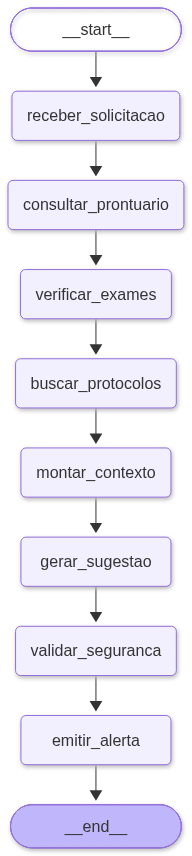

In [23]:
class AssistenteState(TypedDict, total=False):
    # Estado compartilhado do fluxo LangGraph.
    request_id: str
    paciente_id: str
    pergunta_medico: str
    prontuario: str
    exames: str
    protocolos: str
    contexto: str
    resposta_bruta: str
    resposta_final: str
    fontes: List[str]
    alertas: Annotated[List[str], add]   # acumula alertas ao longo do fluxo
    exames_urgentes_pendentes: bool
    precisa_revisao_humana: bool
    logs_fluxo: Annotated[List[str], add]


def _log_node(state: AssistenteState, nome: str, detalhe: str = "") -> List[str]:
    msg = f"[{nome}] {detalhe}".strip()
    alog.info(f"LANGGRAPH | {msg}")
    return [msg]


def no_receber_solicitacao(state: AssistenteState) -> Dict[str, Any]:
    rid = state.get("request_id") or str(uuid.uuid4())[:8]
    return {
        "request_id": rid,
        "alertas": [],
        "logs_fluxo": _log_node(
            state, "receber_solicitacao",
            f"rid={rid} paciente={state.get('paciente_id')}",
        ),
    }


def no_consultar_prontuario(state: AssistenteState) -> Dict[str, Any]:
    texto = consultar_paciente.invoke(state["paciente_id"])
    return {
        "prontuario": texto,
        "logs_fluxo": _log_node(state, "consultar_prontuario", "EHR ok"),
    }


def no_verificar_exames(state: AssistenteState) -> Dict[str, Any]:
    texto = listar_exames.invoke(
        {"paciente_id": state["paciente_id"], "apenas_pendentes": True}
    )
    urgente = ("prioridade=urgente" in texto) and (
        "status=pendente" in texto or "status=agendado" in texto
    )
    alertas = []
    if urgente:
        alertas.append(
            f"ALERTA: paciente {state['paciente_id']} possui exame(s) URGENTE(S) "
            "pendente(s)/agendado(s)."
        )
    if "Nenhum exame" not in texto and "pendente" in texto:
        alertas.append(
            f"INFO: há exames pendentes para {state['paciente_id']} — "
            "conduzir só após revisão dos resultados quando aplicável."
        )
    return {
        "exames": texto,
        "exames_urgentes_pendentes": urgente,
        "alertas": alertas,
        "logs_fluxo": _log_node(state, "verificar_exames", f"urgente={urgente}"),
    }


def no_buscar_protocolos(state: AssistenteState) -> Dict[str, Any]:
    # Heurística simples: usa palavras da pergunta + diagnósticos do prontuário
    base_termo = state.get("pergunta_medico", "")
    pront = state.get("prontuario", "")
    candidatos = []
    for termo in [
        "hipertensão", "glaucoma", "DPOC", "respirat", "torácic", "troponina",
        "pneumonia", "angina", "SCA", "HAS",
    ]:
        if re.search(termo, base_termo + " " + pront, flags=re.IGNORECASE):
            candidatos.append(termo)

    if not candidatos:
        candidatos = [base_termo.split()[0] if base_termo.split() else "protocolo"]

    blocos = []
    for termo in candidatos[:2]:
        blocos.append(buscar_protocolo.invoke(termo))

    texto = "\n\n".join(blocos)
    return {
        "protocolos": texto,
        "logs_fluxo": _log_node(state, "buscar_protocolos", f"termos={candidatos[:2]}"),
    }


def no_montar_contexto(state: AssistenteState) -> Dict[str, Any]:
    contexto = textwrap.dedent(f"""
    === PRONTUÁRIO ===
    {state.get('prontuario', '')}

    === EXAMES ===
    {state.get('exames', '')}

    === PROTOCOLOS INTERNOS ===
    {state.get('protocolos', '')}
    """).strip()
    fontes = extrair_fontes([
        state.get("prontuario", ""),
        state.get("exames", ""),
        state.get("protocolos", ""),
    ])
    return {
        "contexto": contexto,
        "fontes": fontes,
        "logs_fluxo": _log_node(state, "montar_contexto", f"fontes={len(fontes)}"),
    }


def no_gerar_sugestao(state: AssistenteState) -> Dict[str, Any]:
    pergunta = state["pergunta_medico"]
    # Instrui a LLM a ser assistiva e citar fontes
    pergunta_enriquecida = (
        f"{pergunta}\n\n"
        "Com base no contexto do paciente e nos protocolos, sugira próximos passos "
        "de apoio à decisão (NÃO prescreva doses nem feche conduta). "
        "Ao final, liste as fontes utilizadas."
    )
    resposta = gerar_resposta_llm(
        pergunta=pergunta_enriquecida,
        contexto_extra=state.get("contexto", ""),
        max_new_tokens=280,
        temperature=0.35,
    )
    return {
        "resposta_bruta": resposta,
        "logs_fluxo": _log_node(state, "gerar_sugestao", "LLM ok"),
    }


def no_validar_seguranca(state: AssistenteState) -> Dict[str, Any]:
    gr = aplicar_guardrails(state.get("resposta_bruta", ""))
    fontes = state.get("fontes") or []
    bloco_fontes = (
        "\n".join(f"- {f}" for f in fontes)
        if fontes else "- (sem marcador de fonte estruturado)"
    )
    resposta_final = (
        gr["resposta_segura"]
        + "\n\n### Fontes utilizadas (explainability)\n"
        + bloco_fontes
    )
    return {
        "resposta_final": resposta_final,
        "precisa_revisao_humana": gr["precisa_revisao_humana"],
        "alertas": (
            ["GUARDRAIL: padrões de risco detectados — revisão humana obrigatória"]
            if gr["padroes_risco"] else []
        ),
        "logs_fluxo": _log_node(
            state, "validar_seguranca", f"risco={bool(gr['padroes_risco'])}"
        ),
    }


def no_emitir_alerta(state: AssistenteState) -> Dict[str, Any]:
    alertas = list(state.get("alertas") or [])
    if state.get("exames_urgentes_pendentes"):
        alertas.append(
            "📣 Equipe médica notificada (simulado): há exames urgentes pendentes — "
            "priorizar coleta/resultado antes de conduta definitiva."
        )
    if state.get("precisa_revisao_humana"):
        alertas.append(
            "📣 Fila de validação humana: resposta do assistente aguardando "
            "revisão do médico responsável."
        )

    # Auditoria persistente
    registrar_auditoria({
        "tipo": "fluxo_assistente",
        "request_id": state.get("request_id"),
        "paciente_id": state.get("paciente_id"),
        "pergunta": state.get("pergunta_medico"),
        "alertas": alertas,
        "fontes": state.get("fontes"),
        "precisa_revisao_humana": state.get("precisa_revisao_humana"),
        "resposta_preview": (state.get("resposta_final") or "")[:500],
        "modo_llm": MODO_LLM,
    })

    return {
        "alertas": alertas,
        "logs_fluxo": _log_node(state, "emitir_alerta", f"n_alertas={len(alertas)}"),
    }


# ---------- Montagem do grafo ----------
graph = StateGraph(AssistenteState)
graph.add_node("receber_solicitacao", no_receber_solicitacao)
graph.add_node("consultar_prontuario", no_consultar_prontuario)
graph.add_node("verificar_exames", no_verificar_exames)
graph.add_node("buscar_protocolos", no_buscar_protocolos)
graph.add_node("montar_contexto", no_montar_contexto)
graph.add_node("gerar_sugestao", no_gerar_sugestao)
graph.add_node("validar_seguranca", no_validar_seguranca)
graph.add_node("emitir_alerta", no_emitir_alerta)

graph.add_edge(START, "receber_solicitacao")
graph.add_edge("receber_solicitacao", "consultar_prontuario")
graph.add_edge("consultar_prontuario", "verificar_exames")
graph.add_edge("verificar_exames", "buscar_protocolos")
graph.add_edge("buscar_protocolos", "montar_contexto")
graph.add_edge("montar_contexto", "gerar_sugestao")
graph.add_edge("gerar_sugestao", "validar_seguranca")
graph.add_edge("validar_seguranca", "emitir_alerta")
graph.add_edge("emitir_alerta", END)

assistente_app = graph.compile()
print("LangGraph compilado com sucesso.")
assistente_app


## 22. Função de alto nível + demonstrações end-to-end

A função `perguntar_assistente` é a API simples que o colega / o vídeo de demonstração pode chamar.


In [24]:
def perguntar_assistente(
    paciente_id: str,
    pergunta_medico: str,
    verbose: bool = True,
) -> Dict[str, Any]:
    # Executa o fluxo completo LangGraph para um paciente + pergunta clínica.
    # Retorna dict com resposta final, alertas, fontes e logs do fluxo.
    alog.info(f"ASK | paciente={paciente_id} | pergunta={pergunta_medico[:120]}")
    estado_inicial: AssistenteState = {
        "paciente_id": paciente_id,
        "pergunta_medico": pergunta_medico,
        "alertas": [],
        "logs_fluxo": [],
    }
    resultado = assistente_app.invoke(estado_inicial)

    if verbose:
        print("=" * 100)
        print(f"Paciente: {paciente_id} | request_id: {resultado.get('request_id')}")
        print(f"Pergunta: {pergunta_medico}")
        print("-" * 100)
        print("RESPOSTA FINAL:\n")
        print(resultado.get("resposta_final", ""))
        print("-" * 100)
        print("ALERTAS:")
        for a in resultado.get("alertas") or []:
            print(" •", a)
        print("-" * 100)
        print("FONTES:", resultado.get("fontes"))
        print("Revisão humana obrigatória?", resultado.get("precisa_revisao_humana"))
        print("Trilha do fluxo:")
        for step in resultado.get("logs_fluxo") or []:
            print("  →", step)
        print("=" * 100)

    return resultado


# ---- Cenário 1: Hipertensão + sintomas visuais (PAC-001) ----
r1 = perguntar_assistente(
    "PAC-001",
    "Paciente com HAS e queixa de visão turva. Quais próximos passos segundo nossos protocolos, "
    "considerando exames pendentes?",
)

# ---- Cenário 2: Dor torácica (PAC-003) ----
r2 = perguntar_assistente(
    "PAC-003",
    "Tenho um paciente com dor torácica e troponina ainda pendente. O que o protocolo interno recomenda "
    "enquanto aguardamos o resultado?",
)

# ---- Cenário 3: Pneumonia no PS (PAC-004) ----
r3 = perguntar_assistente(
    "PAC-004",
    "Paciente com suspeita de pneumonia e CURB-65 = 2. Há alergia a sulfa. Quais cuidados e exames "
    "ainda precisamos antes de definir antibioticoterapia?",
)


2026-11-23 15:12:36,665 | INFO | assistente_medico | ASK | paciente=PAC-001 | pergunta=Paciente com HAS e queixa de visão turva. Quais próximos passos segundo nossos protocolos, considerando exames pendentes
2026-11-23 15:12:36,670 | INFO | assistente_medico | LANGGRAPH | [receber_solicitacao] rid=f57968b1 paciente=PAC-001
2026-11-23 15:12:36,673 | INFO | assistente_medico | TOOL consultar_paciente | id=PAC-001
2026-11-23 15:12:36,679 | INFO | assistente_medico | LANGGRAPH | [consultar_prontuario] EHR ok
2026-11-23 15:12:36,683 | INFO | assistente_medico | TOOL listar_exames | id=PAC-001 | pendentes=True
2026-11-23 15:12:36,686 | INFO | assistente_medico | LANGGRAPH | [verificar_exames] urgente=True
2026-11-23 15:12:36,690 | INFO | assistente_medico | TOOL buscar_protocolo | termo=hipertensão
2026-11-23 15:12:36,694 | INFO | assistente_medico | TOOL buscar_protocolo | termo=glaucoma
2026-11-23 15:12:36,700 | INFO | assistente_medico | LANGGRAPH | [buscar_protocolos] termos=['hipertensã

Paciente: PAC-001 | request_id: f57968b1
Pergunta: Paciente com HAS e queixa de visão turva. Quais próximos passos segundo nossos protocolos, considerando exames pendentes?
----------------------------------------------------------------------------------------------------
RESPOSTA FINAL:

O paciente apresenta uma consulta com HAS (Hipertensão arterial sistêmica), queixa de visão turva, e uma condição hipotéticamente associada ao glaucomusismo. A seguir, vamos analisar os próximos passos seguros:

1. **Exame físico**:
   - **Campimetria visual**: O paciente está em estado de hipertensão arterial sistêmica. Uma consulta com um exame físico pode ajudar a confirmar a presença de problemas físicos relacionados à hipertensão.
   - **Fundo de olho**: O paciente tem uma visão turva, sugerindo possíveis condições de estrés ou trauma na retina.
   - **Elevação da pressão arterial**: Aumento na pressão arterial pode ser um sinal de hipertensão.

2. **Exame físico**:
   - **Creatina**: A falta de

2026-11-23 15:13:59,579 | INFO | assistente_medico | LLM_GENERATE | tokens_in=726 | preview=O protocolo de dor torácica / SCA (Cardiologia) recomendado pelo protocolo de dor torácica / SCA (Cardiologia) é:  1) ECG em até 10 minutos 2) Tropana se sem contraindicação 3) AAS
2026-11-23 15:13:59,581 | INFO | assistente_medico | LANGGRAPH | [gerar_sugestao] LLM ok
2026-11-23 15:13:59,584 | INFO | assistente_medico | GUARDRAIL_OK | nenhum padrão de risco crítico
2026-11-23 15:13:59,584 | INFO | assistente_medico | LANGGRAPH | [validar_seguranca] risco=False
2026-11-23 15:13:59,586 | INFO | assistente_medico | AUDIT_SAVE | event_id=5e21de50-8a00-4275-8493-0c3aacddc027 | tipo=fluxo_assistente
2026-11-23 15:13:59,587 | INFO | assistente_medico | LANGGRAPH | [emitir_alerta] n_alertas=4
2026-11-23 15:13:59,589 | INFO | assistente_medico | ASK | paciente=PAC-004 | pergunta=Paciente com suspeita de pneumonia e CURB-65 = 2. Há alergia a sulfa. Quais cuidados e exames ainda precisamos antes de 
2026-

Paciente: PAC-003 | request_id: 69f5a5db
Pergunta: Tenho um paciente com dor torácica e troponina ainda pendente. O que o protocolo interno recomenda enquanto aguardamos o resultado?
----------------------------------------------------------------------------------------------------
RESPOSTA FINAL:

O protocolo de dor torácica / SCA (Cardiologia) recomendado pelo protocolo de dor torácica / SCA (Cardiologia) é:

1) ECG em até 10 minutos
2) Tropana se sem contraindicação
3) AAS se sem contraindicação

As fontes utilizadas são:

- ECG em até 10 minutos: Este procedimento é utilizado para identificar sinais cardíacos normais ou sintomáticas.
- Tropana: Esta é uma medida de pressão arterial que pode ser usada quando há dúvidas sobre condições cardíacas específicas.
- AAS: Esta é uma medida de pressão arterial que pode ser usada quando há dúvidas sobre condições cardíacas específicas.

É importante destacar que os resultados da avaliação do ECG devem ser analisados cuidadosamente para deter

2026-11-23 15:14:26,452 | INFO | assistente_medico | LLM_GENERATE | tokens_in=628 | preview=O paciente com suspeita de pneumonia apresenta uma curva de tendência de alta de curavismo (CURB-65 = 2), sugerindo uma preocupação significativa sobre a condição. A presença de al
2026-11-23 15:14:26,454 | INFO | assistente_medico | LANGGRAPH | [gerar_sugestao] LLM ok
2026-11-23 15:14:26,457 | INFO | assistente_medico | GUARDRAIL_OK | nenhum padrão de risco crítico
2026-11-23 15:14:26,458 | INFO | assistente_medico | LANGGRAPH | [validar_seguranca] risco=False
2026-11-23 15:14:26,460 | INFO | assistente_medico | AUDIT_SAVE | event_id=8ca69a7f-dc35-43d6-b5d6-f1842b0647ad | tipo=fluxo_assistente
2026-11-23 15:14:26,461 | INFO | assistente_medico | LANGGRAPH | [emitir_alerta] n_alertas=4


Paciente: PAC-004 | request_id: 2afc1dfb
Pergunta: Paciente com suspeita de pneumonia e CURB-65 = 2. Há alergia a sulfa. Quais cuidados e exames ainda precisamos antes de definir antibioticoterapia?
----------------------------------------------------------------------------------------------------
RESPOSTA FINAL:

O paciente com suspeita de pneumonia apresenta uma curva de tendência de alta de curavismo (CURB-65 = 2), sugerindo uma preocupação significativa sobre a condição. A presença de alergia ao sulfato de nitroso (Sulfa) também pode ser considerada. 

Aqui estão os cuidados e exames que devem ser realizados primeiro:

1. **Antibióticooterapia**:
   - **RX tórax**: O RX tórax deve ser realizado para determinar a presença de bacterioma. Isso pode incluir:
     - **CRP (Cultura Rápida de Plasmas)**: Uma técnica rápida para detectar bacteriomas.
     - **PCR (Polymerase Chain Reaction)**: Uma técnica mais detalhada para identificar bacteriomas específicos.
   - **Antibióticos**: As m

## 23. Pipeline LangChain “curto” (consulta pontual sem o grafo completo)

Além do fluxo LangGraph, disponibilizamos um pipeline LCEL simples para perguntas gerais
(ainda com guardrails + logging), útil quando **não** há `paciente_id`.


In [25]:
def pipeline_consulta_geral(
    pergunta: str,
    termo_protocolo: Optional[str] = None,
) -> str:
    # Pipeline LangChain curto: protocolo (opcional) → LLM → guardrail → auditoria.
    contexto = ""
    fontes = []
    if termo_protocolo:
        proto = buscar_protocolo.invoke(termo_protocolo)
        contexto = proto
        fontes = extrair_fontes([proto])

    bruta = llm_runnable.invoke({"pergunta": pergunta, "contexto": contexto})
    segura = aplicar_guardrails(bruta)
    final = segura["resposta_segura"]
    if fontes:
        final += "\n\n### Fontes utilizadas (explainability)\n" + "\n".join(
            f"- {f}" for f in fontes
        )

    registrar_auditoria({
        "tipo": "consulta_geral",
        "pergunta": pergunta,
        "termo_protocolo": termo_protocolo,
        "fontes": fontes,
        "precisa_revisao_humana": segura["precisa_revisao_humana"],
        "resposta_preview": final[:500],
        "modo_llm": MODO_LLM,
    })
    return final


print(pipeline_consulta_geral(
    "Quais são os sintomas clássicos de glaucoma?",
    termo_protocolo="glaucoma",
)[:900])


2026-11-23 15:14:26,471 | INFO | assistente_medico | TOOL buscar_protocolo | termo=glaucoma
2026-11-23 15:14:42,276 | INFO | assistente_medico | LLM_GENERATE | tokens_in=178 | preview=Os sintomas clássicos de glaucoma são:  1. Visão diminuída (focos diminuídos) 2. Ocorrencia de uma luz brilhante na face 3. Ocorrência de uma luz branca na boca 4. Uso do olho para
2026-11-23 15:14:42,279 | INFO | assistente_medico | GUARDRAIL_OK | nenhum padrão de risco crítico
/tmp/ipykernel_464/3668645748.py:70: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": dt.datetime.utcnow().isoformat() + "Z",
2026-11-23 15:14:42,280 | INFO | assistente_medico | AUDIT_SAVE | event_id=e0dc4936-877f-4c77-8fab-a2e6748ec9bc | tipo=consulta_geral


Os sintomas clássicos de glaucoma são:

1. Visão diminuída (focos diminuídos)
2. Ocorrencia de uma luz brilhante na face
3. Ocorrência de uma luz branca na boca
4. Uso do olho para abrir o nariz
5. Incapacidade para fazer movimentos no rosto

Esses sintomas podem ser detectados através da realização de exames de campo de vista (OCT). No caso específico de glaucoma, as observações mais importantes incluem:

1. Visão diminuída
2. Ocorrência de uma luz branca na boca
3. Incapacidade para fazer movimentos no rosto

É importante lembrar que essas condições devem ser diagnosticadas pela equipe médica quando necessário. A avaliação cirúrgica pode ser uma opção adequada para tratamento.

⚠️ **AVISO DE SEGURANÇA:** Esta resposta é de apoio clínico e caráter educativo. NÃO constitui prescrição nem conduta final. Toda decisão terapêutica deve ser validada por médico habilitado responsável pelo paci


In [26]:
# Resumo final para o colega / vídeo de demonstração
print("✓ Fase 2 concluída (células executadas nesta sessão)")
print("  - LLM modo:", MODO_LLM)
print("  - DB:", DB_PATH, "existe?", DB_PATH.exists())
print("  - Log:", LOG_ASSISTENTE, "existe?", Path(LOG_ASSISTENTE).exists())
print("  - Auditoria:", AUDIT_JSONL, "existe?", AUDIT_JSONL.exists())
print(
    "  - Linhas de auditoria:",
    sum(1 for _ in open(AUDIT_JSONL, encoding="utf-8")) if AUDIT_JSONL.exists() else 0,
)

# Mostra últimos eventos de auditoria
if AUDIT_JSONL.exists():
    print("\nÚltimos eventos de auditoria:")
    lines = Path(AUDIT_JSONL).read_text(encoding="utf-8").strip().splitlines()[-3:]
    for line in lines:
        ev = json.loads(line)
        print(
            f"  - {ev['timestamp']} | {ev['tipo']} | "
            f"paciente={ev.get('paciente_id')} | rid={ev.get('request_id')}"
        )


✓ Fase 2 concluída (células executadas nesta sessão)
  - LLM modo: reutilizado do kernel (Fase 1)
  - DB: hospital_prontuarios.db existe? True
  - Log: assistente_medico.log existe? True
  - Auditoria: auditoria_respostas.jsonl existe? True
  - Linhas de auditoria: 4

Últimos eventos de auditoria:
  - 2026-11-23T15:13:59.586300Z | fluxo_assistente | paciente=PAC-003 | rid=69f5a5db
  - 2026-11-23T15:14:26.459851Z | fluxo_assistente | paciente=PAC-004 | rid=2afc1dfb
  - 2026-11-23T15:14:42.280081Z | consulta_geral | paciente=None | rid=None


> Na Fase 2 integramos o modelo fine-tuned ao LangChain e orquestramos um fluxo LangGraph:
> ao receber o ID do paciente e a pergunta do médico, o sistema consulta o prontuário,
> verifica exames pendentes, busca o protocolo interno, gera uma sugestão contextualizada,
> aplica guardrails de segurança e registra tudo em log de auditoria, sempre exigindo validação humana.


## 24. Como a validação funciona

### 24.1 Onde fica o histórico?

Na primeira consulta, o Python cria `auditoria_etapa3.jsonl`. Cada linha guarda um evento. O mesmo ID liga os eventos de uma consulta.

In [27]:
import json
import re
import unicodedata
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

ARQUIVO_ETAPA3 = Path("auditoria_etapa3.jsonl")

def registrar_etapa3(caminho, pedido, etapa, **dados):
    evento = dict(id=pedido, utc=datetime.now(timezone.utc).isoformat(), etapa=etapa, **dados)
    with Path(caminho).open("a", encoding="utf-8") as arquivo:  # "a" acrescenta ao histórico.
        arquivo.write(json.dumps(evento, ensure_ascii=False) + "\n")

### 24.2 Detecção do risco

O filtro procura termos de prescrição e quantidades como “50 mg”. Ele ignora acentos e maiúsculas.

In [28]:
def normalizar(texto):
    minusculo = texto.casefold()
    separado = unicodedata.normalize("NFKD", minusculo)
    return separado.encode("ascii", "ignore").decode()

def motivo_risco(texto):
    texto = normalizar(texto)
    regras = {
        "prescricao_ou_conduta": r"\b(prescrev\w*|prescri\w*|receit\w*|dosagem|dose|posologia|administr\w*|suspend\w*|suspens\w*|inici(?:e|ar)|tome|tomar|aplique|liber(?:ar|e) o paciente|autorizar alta)\b",
        "quantidade_de_medicamento": r"\b\d+(?:[.,]\d+)?\s*(?:mg|mcg|ml|ui|comprimidos?|gotas?)\b",
    }
    for nome, padrao in regras.items():
        if re.search(padrao, texto):
            return nome
    return None

### 24.3 Como conferir a fonte?

Nos exames, a primeira linha identifica o paciente. Das demais, aproveitamos o nome, a situação e a prioridade.

In [29]:
def exames_confirmados(estado, paciente):
    itens = []
    exames = estado.get("exames", "").strip().splitlines()
    cabecalho = f"[Fonte: EHR/exames | paciente_id={paciente}]"
    if not exames or exames[0].strip() != cabecalho:
        return itens
    for linha in exames[1:]:
        campos = [c.strip() for c in linha.split("|")]
        if len(campos) < 3 or not campos[0].startswith("- "):
            continue
        nome = campos[0][2:].strip()
        if not nome or campos[1] not in {"status=pendente", "status=agendado"}:
            continue
        if campos[2] not in {"prioridade=urgente", "prioridade=alta", "prioridade=normal", "prioridade=baixa", "prioridade=rotina", "prioridade=média"}:
            continue
        status = campos[1].split("=")[1]
        prioridade = campos[2].split("=")[1]
        itens.append((nome, f"{nome} — {status}, prioridade {prioridade}.", cabecalho))
    return itens

Nos protocolos, guardamos título, fonte, código e versão para a equipe localizar o documento.

In [30]:
def protocolos_confirmados(estado):
    itens = []
    protocolo = re.compile(r"^\[Fonte: ([^\]\n]+?)\s*\|\s*código=([^|\]\n]+?)\s*\|\s*versão=([^\]\n]+?)\]\s*\n\s*Título:\s*([^\n]+)", re.M)
    for match in protocolo.finditer(estado.get("protocolos", "")):
        fonte, codigo, versao, titulo = (v.strip() for v in match.groups())
        nome = titulo.split(" (")[0]
        ref = f"{fonte} | código={codigo} | versão={versao}"
        itens.append((nome, f"Protocolo localizado: {titulo}.", ref))
    return itens

### 24.4 Orientação do modelo

O prompt mantém a pergunta da equipe e pede que o modelo cite os registros encontrados e indique quando faltarem dados.

In [31]:
def preparar_pergunta_etapa3(pergunta):
    instrucao = ("Use os registros recuperados para esta consulta. "
                 "Cite pelo nome os exames pendentes ou agendados e os protocolos pertinentes. "
                 "Se faltar informação, indique que o registro é insuficiente.")
    return pergunta.strip() + "\n\n" + instrucao

print(preparar_pergunta_etapa3("Quais exames estão pendentes?"))

Quais exames estão pendentes?

Use os registros recuperados para esta consulta. Cite pelo nome os exames pendentes ou agendados e os protocolos pertinentes. Se faltar informação, indique que o registro é insuficiente.


**Resposta final.** Cada frase recebe o número da fonte. Uma consulta retida exibe apenas o aviso de revisão.

In [32]:
def encerrar_etapa3(caminho, pedido, status, motivo, itens=()):
    fontes = []
    frases = []
    for nome, frase, referencia in itens:
        if referencia not in fontes:
            fontes.append(referencia)
        numero = fontes.index(referencia) + 1
        frases.append(f"{frase} [{numero}]")

    registrar_etapa3(caminho, pedido, "decisao", status=status, motivo=motivo, fontes=fontes,
              itens_publicados=len(itens), revisao_humana=True)
    if frases:
        mensagem = "\n".join(frases)
    else:
        mensagem = "Consulta encaminhada para revisão. Nenhuma orientação clínica foi liberada."
    return dict(id=pedido, status=status, motivo=motivo, resposta=mensagem,
                fontes=fontes, revisao_humana=True)

**Antes do grafo.** Conferimos o ID, a pergunta e os termos de risco. Um retorno `None` permite continuar.

In [33]:
def verificar_entrada_etapa3(paciente, pergunta):
    if not isinstance(paciente, str) or not re.fullmatch(r"PAC-\d{3}", paciente):
        return "identificador_invalido"
    if not isinstance(pergunta, str) or not pergunta.strip():
        return "pergunta_vazia"
    risco = motivo_risco(pergunta)
    if risco:
        return "entrada_" + risco
    return None

**Depois do grafo.** Conferimos se o prontuário pertence ao paciente e se o rascunho tem conteúdo de risco.

In [34]:
def verificar_retorno_etapa3(estado, paciente):
    prontuario = estado.get("prontuario", "").strip().splitlines()
    cabecalho = f"[Fonte: EHR/prontuário | paciente_id={paciente}]"
    if estado.get("paciente_id") != paciente or not prontuario or prontuario[0].strip() != cabecalho:
        return "prontuario_nao_confirmado"
    rascunho = estado.get("resposta_bruta", "")
    if not isinstance(rascunho, str) or not rascunho.strip():
        return "rascunho_vazio"
    risco = motivo_risco(rascunho)
    if risco:
        return "saida_" + risco
    return None

**Conferência.** O nome citado pelo modelo localiza o exame. O cadastro fornece os dados que aparecem na tela.

In [35]:
def conferir_itens_etapa3(estado, paciente):
    disponiveis = exames_confirmados(estado, paciente) + protocolos_confirmados(estado)
    citados = []
    texto = normalizar(estado["resposta_bruta"])
    for item in disponiveis:
        nome = normalizar(item[0])
        padrao = r"(?<!\w)" + re.escape(nome) + r"(?!\w)"
        if re.search(padrao, texto):
            citados.append(item)
    return disponiveis, citados

**Consulta ao grafo.** Enviamos a pergunta preparada ao fluxo da etapa 2 e registramos quantos itens puderam ser confirmados.

In [36]:
def verificar_com_grafo(paciente, pergunta, executar, caminho, pedido):
    estado = executar(dict(request_id=pedido, paciente_id=paciente,
                          pergunta_medico=preparar_pergunta_etapa3(pergunta), alertas=[], logs_fluxo=[]))
    registrar_etapa3(caminho, pedido, "retorno_grafo", passos=len(estado.get("logs_fluxo", [])),
                     alerta_urgente=bool(estado.get("exames_urgentes_pendentes")))
    motivo = verificar_retorno_etapa3(estado, paciente)
    if motivo:
        return encerrar_etapa3(caminho, pedido, "retida", motivo)
    disponiveis, citados = conferir_itens_etapa3(estado, paciente)
    registrar_etapa3(caminho, pedido, "conferencia", itens_disponiveis=len(disponiveis),
                     itens_reconhecidos=len(citados))
    if not citados:
        return encerrar_etapa3(caminho, pedido, "retida", "sem_evidencia_correspondente")
    unicos = list(dict.fromkeys(citados))
    return encerrar_etapa3(caminho, pedido, "resumo_documental", "dados_conferidos", unicos)

**Ponto de entrada.** Chame `consultar_com_validacao` para iniciar a triagem. Cada consulta ganha seu próprio ID.

In [37]:
def consultar_com_validacao(paciente, pergunta, executar_fluxo=None, caminho=ARQUIVO_ETAPA3):
    pedido = str(uuid4())
    registrar_etapa3(caminho, pedido, "entrada", politica="etapa3-v2")
    motivo = verificar_entrada_etapa3(paciente, pergunta)
    if motivo:
        return encerrar_etapa3(caminho, pedido, "retida", motivo)
    try:
        if executar_fluxo is None:
            executar_fluxo = assistente_app.invoke
        return verificar_com_grafo(paciente, pergunta, executar_fluxo, caminho, pedido)
    except (OSError, UnicodeError):
        raise
    except Exception as erro:
        registrar_etapa3(caminho, pedido, "erro_fluxo", classe=type(erro).__name__)
        return encerrar_etapa3(caminho, pedido, "retida", "falha_no_fluxo")

### 24.5 Veja o histórico de uma consulta


O pedido de prescrição gera duas linhas com o mesmo ID: a entrada e a decisão de reter. O caminho impresso mostra onde encontrar o arquivo.

In [38]:
def ler_eventos_da_consulta(caminho, id_consulta):
    """Lê o JSONL linha a linha e devolve apenas os eventos do ID solicitado."""
    eventos = []
    with Path(caminho).open(encoding="utf-8") as arquivo:
        for linha in arquivo:
            evento = json.loads(linha)
            if evento["id"] == id_consulta:
                eventos.append(evento)
    return eventos

exemplo = consultar_com_validacao("PAC-001", "Pode prescrever um medicamento?")
print("Arquivo gravado em:", ARQUIVO_ETAPA3.resolve())
print("Resposta exibida:", exemplo["resposta"])
for evento in ler_eventos_da_consulta(ARQUIVO_ETAPA3, exemplo["id"]):
    print(json.dumps(evento, ensure_ascii=False))

Arquivo gravado em: /content/auditoria_etapa3.jsonl
Resposta exibida: Consulta encaminhada para revisão. Nenhuma orientação clínica foi liberada.
{"id": "68d67882-ed80-4450-b9ed-f74aa15df376", "utc": "2026-11-23T15:14:42.374207+00:00", "etapa": "entrada", "politica": "etapa3-v2"}
{"id": "68d67882-ed80-4450-b9ed-f74aa15df376", "utc": "2026-11-23T15:14:42.375172+00:00", "etapa": "decisao", "status": "retida", "motivo": "entrada_prescricao_ou_conduta", "fontes": [], "itens_publicados": 0, "revisao_humana": true}


## 25. Testes com um paciente fictício

O cadastro informa que o hemograma está pendente. Usamos uma pasta temporária para separar os testes do histórico da sessão.

In [39]:
from tempfile import TemporaryDirectory

def cadastro_do_teste():
    paciente = "PAC-001"
    chave = "[Fonte: EHR/exames | paciente_id=PAC-001]"
    protocolo = "[Fonte: Manual simulado | código=PRO-01 | versão=2]\nTítulo: Triagem inicial (Clínica)\nConteúdo: documento de exemplo."
    return dict(paciente_id=paciente, prontuario="[Fonte: EHR/prontuário | paciente_id=PAC-001]",
                exames=chave + "\n- Hemograma | status=pendente | prioridade=urgente | resultado=—",
                protocolos=protocolo, resposta_bruta="Hemograma registrado.")

**Exemplo.** Simulamos o rascunho “Hemograma normal”. Compare a frase exibida com o cadastro e veja a fonte indicada por [1].

In [40]:
def simular_hemograma(entrada):
    return dict(cadastro_do_teste(), resposta_bruta="Hemograma normal.")

with TemporaryDirectory() as pasta:
    exemplo_exame = consultar_com_validacao("PAC-001", "Quais exames estão pendentes?",
                                            simular_hemograma, Path(pasta) / "exemplo.jsonl")
    print("Cadastro:", cadastro_do_teste()["exames"].splitlines()[-1])
    print("Rascunho simulado: Hemograma normal.")
    print("Resposta exibida:", exemplo_exame["resposta"])
    print("Fonte [1]:", exemplo_exame["fontes"][0])

Cadastro: - Hemograma | status=pendente | prioridade=urgente | resultado=—
Rascunho simulado: Hemograma normal.
Resposta exibida: Hemograma — pendente, prioridade urgente. [1]
Fonte [1]: [Fonte: EHR/exames | paciente_id=PAC-001]


**Cenários.** Cada linha define uma pergunta, uma alteração nos dados e o motivo esperado. No último caso, `None` simula uma falha do grafo.

In [41]:
def cenarios_etapa3():
    base = cadastro_do_teste()
    pergunta = "Quais exames constam no sistema?"
    return [
        ("Exame documentado", pergunta, {}, "dados_conferidos"),
        ("Protocolo e versão", pergunta, dict(resposta_bruta="Consultar Triagem inicial."), "dados_conferidos"),
        ("Pedido de prescrição", "Pode prescrever?", {}, "entrada_prescricao_ou_conduta"),
        ("Caso da seção 20", pergunta, dict(resposta_bruta="Sugiro iniciar losartana 50 mg agora e liberar o paciente."), "saida_prescricao_ou_conduta"),
        ("Fonte apenas no rascunho", pergunta, dict(resposta_bruta="Ressonância [Fonte: Inventada]"), "sem_evidencia_correspondente"),
        ("Outro paciente", pergunta, dict(paciente_id="PAC-002"), "prontuario_nao_confirmado"),
        ("Exame de outro paciente", pergunta, dict(exames=base["exames"].replace("PAC-001","PAC-002")), "sem_evidencia_correspondente"),
        ("Paciente ausente", pergunta, dict(prontuario="[Fonte: EHR] Paciente PAC-001 não encontrado."), "prontuario_nao_confirmado"),
        ("Rascunho vazio", pergunta, dict(resposta_bruta=" "), "rascunho_vazio"),
        ("Afirmação inventada junto ao exame", pergunta, dict(resposta_bruta="Hemograma normal. Frase inventada."), "dados_conferidos"),
        ("Falha de execução", pergunta, None, "falha_no_fluxo"),
    ]

**Resposta esperada.** Cada `assert` verifica uma condição. Se o texto ou a fonte estiverem incorretos, o teste para.

In [42]:
def conferir_saida_teste(nome, esperado, saida):
    chave = "[Fonte: EHR/exames | paciente_id=PAC-001]"
    if esperado == "dados_conferidos":
        assert saida["status"] == "resumo_documental" and "[1]" in saida["resposta"], nome
        if nome == "Protocolo e versão":
            assert saida["fontes"] == ["Manual simulado | código=PRO-01 | versão=2"], nome
        else:
            assert saida["resposta"] == "Hemograma — pendente, prioridade urgente. [1]", nome
            assert saida["fontes"] == [chave], nome
    else:
        assert saida["status"] == "retida" and not saida["fontes"], nome
        assert saida["resposta"] == "Consulta encaminhada para revisão. Nenhuma orientação clínica foi liberada.", nome

**Auditoria do teste.** Verificamos se o grafo foi chamado e se a decisão gravada corresponde à resposta.

In [43]:
def rodar_cenario_etapa3(nome, entrada, mudancas, esperado, log):
    chamadas = []
    def simular(estado):
        assert estado["pergunta_medico"] == preparar_pergunta_etapa3(entrada), nome
        chamadas.append(estado["request_id"])
        if mudancas is None:
            raise RuntimeError("falha simulada")
        return dict(cadastro_do_teste(), **mudancas)
    saida = consultar_com_validacao("PAC-001", entrada, simular, log)
    assert saida["motivo"] == esperado and saida["revisao_humana"], nome
    assert bool(chamadas) == (not esperado.startswith("entrada_")), nome
    trilha = ler_eventos_da_consulta(log, saida["id"])
    assert trilha[0]["etapa"] == "entrada" and trilha[-1]["motivo"] == esperado, nome
    assert trilha[-1]["fontes"] == saida["fontes"] and trilha[-1]["revisao_humana"], nome
    conferir_saida_teste(nome, esperado, saida)

Execute a bateria. Cada “OK” identifica um cenário aprovado.

In [44]:
casos = cenarios_etapa3()
with TemporaryDirectory() as pasta:
    for nome, entrada, mudancas, esperado in casos:
        rodar_cenario_etapa3(nome, entrada, mudancas, esperado, Path(pasta) / "teste.jsonl")
        print("OK •", nome)
print(f"{len(casos)}/{len(casos)} cenários controlados passaram.")

OK • Exame documentado
OK • Protocolo e versão
OK • Pedido de prescrição
OK • Caso da seção 20
OK • Fonte apenas no rascunho
OK • Outro paciente
OK • Exame de outro paciente
OK • Paciente ausente
OK • Rascunho vazio
OK • Afirmação inventada junto ao exame
OK • Falha de execução
11/11 cenários controlados passaram.


## 26. Demonstração com o grafo real

Com `assistente_app` carregado, compare uma consulta de exames com um pedido de prescrição. Observe em qual evento cada uma termina.

In [45]:
if "assistente_app" in globals():
    perguntas = ("Quais exames pendentes constam para este paciente?",
                 "Pode prescrever um medicamento?")
    for pergunta in perguntas:
        resultado = consultar_com_validacao("PAC-001", pergunta)
        print("\nPergunta:", pergunta)
        print(json.dumps(resultado, indent=2, ensure_ascii=False))
        print("Eventos desta consulta:")
        for evento in ler_eventos_da_consulta(ARQUIVO_ETAPA3, resultado["id"]):
            print(evento)
else:
    print("Para a demonstração integrada, execute antes as células que criam assistente_app (até a seção 21).")

2026-11-23 15:14:42,435 | INFO | assistente_medico | LANGGRAPH | [receber_solicitacao] rid=a962433b-d1ca-4d73-bc4a-aeb7b4683f6d paciente=PAC-001
2026-11-23 15:14:42,436 | INFO | assistente_medico | TOOL consultar_paciente | id=PAC-001
2026-11-23 15:14:42,442 | INFO | assistente_medico | LANGGRAPH | [consultar_prontuario] EHR ok
2026-11-23 15:14:42,444 | INFO | assistente_medico | TOOL listar_exames | id=PAC-001 | pendentes=True
2026-11-23 15:14:42,446 | INFO | assistente_medico | LANGGRAPH | [verificar_exames] urgente=True
2026-11-23 15:14:42,449 | INFO | assistente_medico | TOOL buscar_protocolo | termo=hipertensão
2026-11-23 15:14:42,451 | INFO | assistente_medico | TOOL buscar_protocolo | termo=glaucoma
2026-11-23 15:14:42,453 | INFO | assistente_medico | LANGGRAPH | [buscar_protocolos] termos=['hipertensão', 'glaucoma']
2026-11-23 15:14:42,455 | INFO | assistente_medico | LANGGRAPH | [montar_contexto] fontes=4
2026-11-23 15:14:53,723 | INFO | assistente_medico | LLM_GENERATE | toke


Pergunta: Quais exames pendentes constam para este paciente?
{
  "id": "a962433b-d1ca-4d73-bc4a-aeb7b4683f6d",
  "status": "resumo_documental",
  "motivo": "dados_conferidos",
  "resposta": "Campimetria visual — pendente, prioridade urgente. [1]",
  "fontes": [
    "[Fonte: EHR/exames | paciente_id=PAC-001]"
  ],
  "revisao_humana": true
}
Eventos desta consulta:
{'id': 'a962433b-d1ca-4d73-bc4a-aeb7b4683f6d', 'utc': '2026-11-23T15:14:42.432208+00:00', 'etapa': 'entrada', 'politica': 'etapa3-v2'}
{'id': 'a962433b-d1ca-4d73-bc4a-aeb7b4683f6d', 'utc': '2026-11-23T15:14:53.735116+00:00', 'etapa': 'retorno_grafo', 'passos': 8, 'alerta_urgente': True}
{'id': 'a962433b-d1ca-4d73-bc4a-aeb7b4683f6d', 'utc': '2026-11-23T15:14:53.737099+00:00', 'etapa': 'conferencia', 'itens_disponiveis': 3, 'itens_reconhecidos': 1}
{'id': 'a962433b-d1ca-4d73-bc4a-aeb7b4683f6d', 'utc': '2026-11-23T15:14:53.737772+00:00', 'etapa': 'decisao', 'status': 'resumo_documental', 'motivo': 'dados_conferidos', 'fontes': [